# 02 Analysis: Track 2, Cardiovascular Health in Women

This notebook follows steps 3 to 7 of the [workflow](../../3-workflow.md): explore, build a model, check it, interpret and make a headline visual. Run `01_cleaning.ipynb` first.

**Our question in one sentence**

> Among about 68,000 adults aged about 40 to 65 in Dataset 1, does the chance of having cardiovascular disease (CVD) rise more steeply with age in women than in men, and does that difference remain after accounting for blood pressure, cholesterol, glucose, BMI and lifestyle?

**Why it matters.** Heart disease in women is often thought of as a problem for later in life, and women have been under-represented in heart research. Many studies report that women's risk climbs after menopause, which usually happens between 45 and 55. If the same pattern shows up in this dataset, it says *when* in life women's risk catches up with men's, which is useful for deciding when to pay closer attention to women's heart health.

**What is in this notebook**

| Section | What it does |
|---|---|
| 1 | Our question, the variables and how each one is encoded |
| 2 | Explore: sample sizes, summary statistics, CVD by age and sex, risk factors by age and sex |
| 3 | Models: the age-by-sex logistic regression (main result), smooth age curves, women-only and men-only models, and four age-adjusted tests (age standardization, age-only vs full adjustment, Cochran-Mantel-Haenszel, before vs after 55) |
| 4 | Checks: cross-validated AUC, calibration, a flexible-age check and eight sensitivity analyses |
| 5 | Interpretation in plain language |
| 6 | Headline visual |
| 7 | Global context from Dataset 3 (countries) |
| 8 | Appendix: why we did not use Dataset 2 |

The whole notebook runs top to bottom in about two minutes.

**How to run.** Download or clone the repository, install the packages with `pip install -r track-02/team/requirements.txt`, open this notebook from `track-02/team/notebooks/` and run it top to bottom. It reads the raw data from `track-02/data/` and saves outputs to `track-02/team/` (`data_clean/`, `figures/` and `docs/cleaning_log.md`). Run `01_cleaning.ipynb` before `02_analysis.ipynb`.


In [1]:
# Setup: run this cell first. It finds the track-02 folder of this repository,
# reads the raw data from track-02/data/ and saves every output in track-02/team/.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TEAM_REPO = "https://github.com/ankit010798verma/HeartBeat-OpenDatathon.git"   # only used on Colab
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    """Walk up from this notebook's folder until we reach track-02."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
    if IN_COLAB:   # opened directly in Colab: download the repository first
        dest = Path("/content") / Path(TEAM_REPO).stem
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", TEAM_REPO, str(dest)], check=True)
        return dest / "track-02"
    raise FileNotFoundError("Could not find the track-02 folder. Open this notebook from "
                            "track-02/team/notebooks/ inside the downloaded repository.")

TRACK = find_track_dir()
TEAM = TRACK / "team"
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)
SEARCH_DIRS = [TRACK / "data", TRACK / "data" / "gbd"]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Outputs go to:", TEAM)


Track folder: HeartBeat-OpenDatathon/track-02
Outputs go to: HeartBeat-OpenDatathon/track-02/team


In [2]:
# Extra tools and a shared plotting style
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold"})
WOMEN_COLOR, MEN_COLOR = "#0b7a5e", "#8a8f96"
SEX_COLORS = {"Women": WOMEN_COLOR, "Men": MEN_COLOR}
SEED = 2026          # fixed seed so bootstraps and cross-validation give the same numbers every run
BOOT_REPS = 200      # bootstrap repetitions for confidence intervals that have no simple formula

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=200, bbox_inches="tight")
    print("Saved", FIGURES / name)

def find_file(name):
    for folder in SEARCH_DIRS:
        p = folder / name
        if p.is_file() and p.stat().st_size > 0:
            return p
    return None

## Step 1: Our question and variables

**Outcome:** `cardio`, whether the person has cardiovascular disease (1 = yes).

**Main comparison:** how the odds of CVD change with age, separately for women and men. In a logistic regression this is an **interaction** between sex and age: a term that lets the age slope be different for women.

**How we encode each predictor.** We rescale numbers so each odds ratio describes a change that means something in everyday terms, and we centre them on familiar reference values so that the "women vs men" term describes a 50-year-old with typical readings.

| Variable | Column we create | One unit means | Reference (value 0) |
|---|---|---|---|
| Age | `age_dec` | 10 years older | Age 50 |
| Sex | `female` | Woman (vs man) | Man |
| Systolic blood pressure | `sbp_10` | 10 mmHg higher | 120 mmHg |
| Cholesterol (ordered: normal < above < well above) | `chol_2`, `chol_3` | Above normal; well above normal | Normal |
| Glucose (same coding) | `gluc_2`, `gluc_3` | Above normal; well above normal | Normal |
| BMI | `bmi_5` | 5 BMI units higher | BMI 25 |
| Smoking, alcohol, physical activity | `smoke`, `alco`, `active` | Yes (self-reported) | No |

Cholesterol and glucose are ordered categories, not measurements, so we give each level its own indicator compared with "normal". This keeps the order meaningful without assuming that the step from level 2 to 3 is the same size as from 1 to 2.

**Why these covariates?** Blood pressure, cholesterol, glucose and BMI are the standard measured risk factors, and they all change with age, so they could explain part of an age pattern. We fit the model with and without them.

We use systolic but not diastolic pressure in the main model because the two are strongly correlated (r about 0.7 here) and systolic is the stronger predictor in middle and older age. A sensitivity check adds diastolic.

In [3]:
QUESTION = ("Among about 68,000 adults aged about 40 to 65 in Dataset 1, does the chance of having cardiovascular disease "
            "rise more steeply with age in women than in men, and does that difference remain after accounting for "
            "blood pressure, cholesterol, glucose, BMI and lifestyle?")
DATASET = "d1"
OUTCOME = "cardio"
MODEL = "logistic"
COVARIATES = ["sbp_10", "chol_2", "chol_3", "gluc_2", "gluc_3", "bmi_5", "smoke", "alco", "active"]
PREDICTORS = ["female", "age_dec", "female:age_dec"] + COVARIATES

LABELS = {
    "age_dec": "10 years older",
    "sbp_10": "Systolic BP 10 mmHg higher",
    "chol_2": "Cholesterol above normal",
    "chol_3": "Cholesterol well above normal",
    "gluc_2": "Glucose above normal",
    "gluc_3": "Glucose well above normal",
    "bmi_5": "BMI 5 units higher",
    "smoke": "Smokes (self-reported)",
    "alco": "Drinks alcohol (self-reported)",
    "active": "Physically active (self-reported)",
}

AGE_BINS = [0, 45, 50, 55, 60, 70]
AGE_BAND_LABELS = ["Under 45", "45-49", "50-54", "55-59", "60-65"]   # only 4 people are under 39

def add_model_columns(d):
    """Create the rescaled model variables described in the table above."""
    d = d.copy()
    d["age_dec"] = (d["age_years"] - 50) / 10
    d["sbp_10"] = (d["ap_hi"] - 120) / 10
    d["dbp_10"] = (d["ap_lo"] - 80) / 10
    d["bmi_5"] = (d["bmi"] - 25) / 5
    for col, short in (("cholesterol", "chol"), ("gluc", "gluc")):
        d[f"{short}_2"] = (d[col] == 2).astype(int)
        d[f"{short}_3"] = (d[col] == 3).astype(int)
    d["sex"] = np.where(d["female"] == 1, "Women", "Men")
    d["age_band"] = pd.cut(d["age_years"], AGE_BINS, labels=AGE_BAND_LABELS, right=False)
    return d

path = CLEAN / f"{DATASET}_clean.csv"
if not path.exists():
    raise FileNotFoundError(f"{path.name} not found. Run 01_cleaning.ipynb first.")
df = add_model_columns(pd.read_csv(path))
data = df.dropna(subset=[OUTCOME, "age_dec", "female"] + COVARIATES).copy()

print(QUESTION, "\n")
print(f"Loaded {len(df):,} rows from {path.name}; {len(data):,} have every variable we use.")
print(data["sex"].value_counts().to_string())
print(f"Correlation between systolic and diastolic BP: {data['ap_hi'].corr(data['ap_lo']):.2f}")

Among about 68,000 adults aged about 40 to 65 in Dataset 1, does the chance of having cardiovascular disease rise more steeply with age in women than in men, and does that difference remain after accounting for blood pressure, cholesterol, glucose, BMI and lifestyle? 

Loaded 68,557 rows from d1_clean.csv; 68,557 have every variable we use.
sex
Women    44648
Men      23909
Correlation between systolic and diastolic BP: 0.73


## Step 2: Explore

### 2a. Who is in the data?

The table compares women and men on every variable we use, but we have to keep in mind:
- **About half of everyone has CVD.** That is far higher than in the general population, so the people in this dataset were not a random sample
- **Very few women report smoking or drinking.** Small groups give wide confidence intervals, so results for those two variables in women are uncertain.
- **The age range is narrow** The data dictionary says ages run from about 30 to 65, but only 4 people are under 39. In practice this dataset covers people aged 39 to 65, so we say nothing about younger or older adults.

In [4]:
def pct(s):
    return 100 * s.mean()

summary = data.groupby("sex").agg(**{
    "People": ("cardio", "size"),
    "Has CVD (%)": ("cardio", pct),
    "Age, mean (years)": ("age_years", "mean"),
    "Systolic BP, median (mmHg)": ("ap_hi", "median"),
    "BMI, mean": ("bmi", "mean"),
    "Cholesterol above normal or higher (%)": ("cholesterol", lambda s: 100 * (s > 1).mean()),
    "Glucose above normal or higher (%)": ("gluc", lambda s: 100 * (s > 1).mean()),
    "Smokes (%)": ("smoke", pct),
    "Drinks alcohol (%)": ("alco", pct),
    "Physically active (%)": ("active", pct),
}).T[["Women", "Men"]]
display(summary.round(1))
print(f"People under 39: {(data['age_years'] < 39).sum()}; 1st percentile of age: {data['age_years'].quantile(0.01):.1f} years")
print(f"Women who report smoking: {int(data.loc[data.female == 1, 'smoke'].sum()):,}; "
      f"women who report drinking: {int(data.loc[data.female == 1, 'alco'].sum()):,}")

sex,Women,Men
People,44648.0,23909.0
Has CVD (%),49.2,50.0
"Age, mean (years)",53.4,53.1
"Systolic BP, median (mmHg)",120.0,120.0
"BMI, mean",27.9,26.7
Cholesterol above normal or higher (%),26.2,22.9
Glucose above normal or higher (%),15.5,14.1
Smokes (%),1.8,21.9
Drinks alcohol (%),2.5,10.6
Physically active (%),80.2,80.7


People under 39: 4; 1st percentile of age: 39.6 years
Women who report smoking: 793; women who report drinking: 1,126


### 2b. How does CVD change with age for women and men?

For each five-year age group we compute the share of people with CVD and a 95% confidence interval (the Wilson method, which works well for percentages). This is the raw pattern before any model.

people            pct          lo          hi      
sex          Men    Women   Men Women   Men Women   Men Women
age_band                                                     
Under 45  3833.0   6253.0  31.6  27.8  30.2  26.7  33.1  28.9
45-49     4187.0   6990.0  45.6  40.8  44.1  39.7  47.1  42.0
50-54     5485.0  11253.0  47.8  45.2  46.5  44.3  49.2  46.1
55-59     5916.0  12150.0  55.8  56.4  54.6  55.6  57.1  57.3
60-65     4488.0   8002.0  64.5  68.0  63.1  66.9  65.9  69.0

Saved HeartBeat-OpenDatathon/track-02/team/figures/observed_by_age_band.png


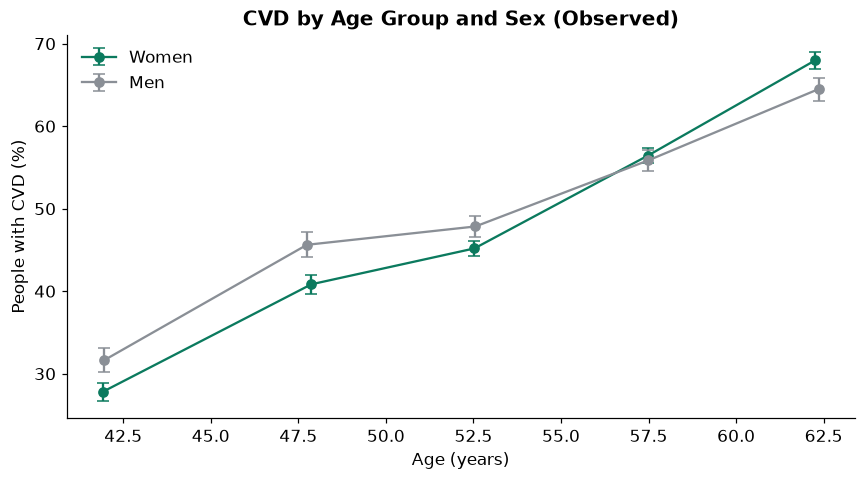

In [5]:
def rate_table(frame, by):
    g = frame.groupby(by, observed=True).agg(cases=("cardio", "sum"), people=("cardio", "size"),
                                             mean_age=("age_years", "mean")).reset_index()
    lo, hi = proportion_confint(g["cases"], g["people"], alpha=0.05, method="wilson")
    g["pct"], g["lo"], g["hi"] = 100 * g["cases"] / g["people"], 100 * lo, 100 * hi
    return g

bands = rate_table(data, ["age_band", "sex"])
display(bands.pivot(index="age_band", columns="sex", values=["people", "pct", "lo", "hi"]).round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for sex in ["Women", "Men"]:
    b = bands[bands["sex"] == sex]
    ax.errorbar(b["mean_age"], b["pct"], yerr=[b["pct"] - b["lo"], b["hi"] - b["pct"]], marker="o",
                capsize=4, color=SEX_COLORS[sex], label=sex)
ax.set_xlabel("Age (years)")
ax.set_ylabel("People with CVD (%)")
ax.set_title("CVD by Age Group and Sex (Observed)")
ax.legend(frameon=False)
plt.tight_layout()
save(fig, "observed_by_age_band.png")
plt.show()

**What we see.** Under age 55, women have a lower rate of CVD than men in every age group, and the confidence intervals do not overlap. In the 55-59 group the rates are about equal, and at 60-65 women's rate is *higher* than men's.

### 2c. Do risk factors change with age differently for women?

If women's blood pressure or cholesterol rise faster with age than men's, that could explain part of the pattern above. The left panel shows mean systolic blood pressure with a 95% confidence interval; the right panel shows the share with above-normal cholesterol.

Saved HeartBeat-OpenDatathon/track-02/team/figures/risk_factors_by_age.png


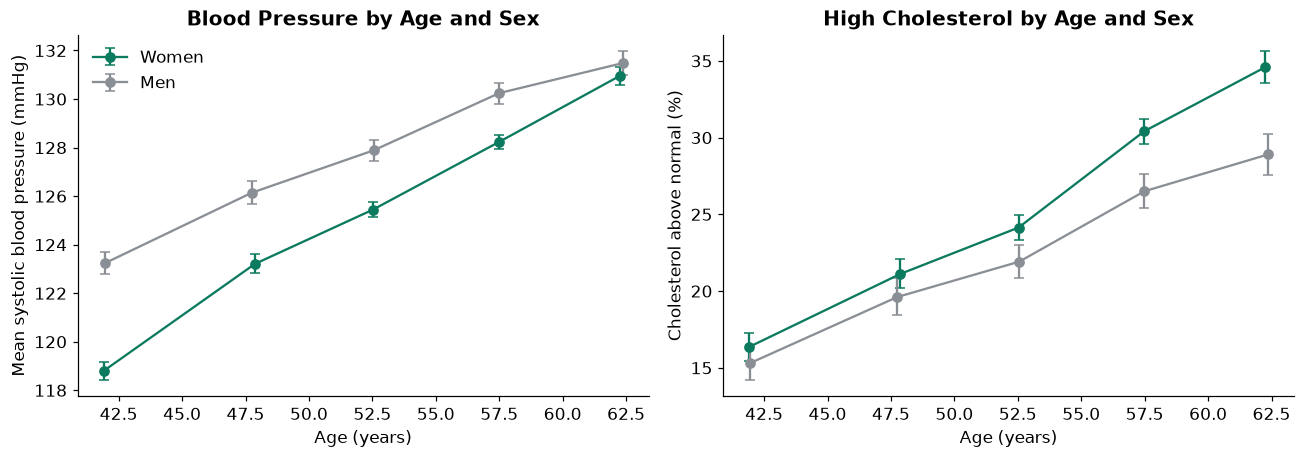

Women: systolic BP rises 12.2 mmHg and high cholesterol 18.2 percentage points from 'Under 45' to '60-65'
Men: systolic BP rises 8.2 mmHg and high cholesterol 13.6 percentage points from 'Under 45' to '60-65'


In [6]:
data["chol_high"] = (data["cholesterol"] > 1).astype(int)
traj = data.groupby(["age_band", "sex"], observed=True).agg(
    mean_age=("age_years", "mean"), sbp=("ap_hi", "mean"), sbp_sd=("ap_hi", "std"),
    n=("ap_hi", "size"), chol_cases=("chol_high", "sum")).reset_index()
traj["sbp_se"] = traj["sbp_sd"] / np.sqrt(traj["n"])
lo, hi = proportion_confint(traj["chol_cases"], traj["n"], method="wilson")
traj["chol_pct"], traj["chol_lo"], traj["chol_hi"] = 100 * traj["chol_cases"] / traj["n"], 100 * lo, 100 * hi

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for sex in ["Women", "Men"]:
    t = traj[traj["sex"] == sex]
    axes[0].errorbar(t["mean_age"], t["sbp"], yerr=1.96 * t["sbp_se"], marker="o", capsize=3,
                     color=SEX_COLORS[sex], label=sex)
    axes[1].errorbar(t["mean_age"], t["chol_pct"], yerr=[t["chol_pct"] - t["chol_lo"], t["chol_hi"] - t["chol_pct"]],
                     marker="o", capsize=3, color=SEX_COLORS[sex], label=sex)
axes[0].set(xlabel="Age (years)", ylabel="Mean systolic blood pressure (mmHg)", title="Blood Pressure by Age and Sex")
axes[1].set(xlabel="Age (years)", ylabel="Cholesterol above normal (%)", title="High Cholesterol by Age and Sex")
axes[0].legend(frameon=False)
plt.tight_layout()
save(fig, "risk_factors_by_age.png")
plt.show()

first, last = AGE_BAND_LABELS[0], AGE_BAND_LABELS[-1]
for sex in ["Women", "Men"]:
    t = traj[traj["sex"] == sex].set_index("age_band")
    print(f"{sex}: systolic BP rises {t.loc[last, 'sbp'] - t.loc[first, 'sbp']:.1f} mmHg and high cholesterol "
          f"{t.loc[last, 'chol_pct'] - t.loc[first, 'chol_pct']:.1f} percentage points from '{first}' to '{last}'")

**What we see.** Women start with lower blood pressure than men but it rises faster, so by 60-65 the two are nearly equal. High cholesterol is about as common in women as in men in their early 40s, but it rises faster in women and the gap widens after 50. Both patterns line up with the CVD pattern in 2b, which is why the adjusted model in Step 3 matters, since it asks whether women's steeper age pattern remains once these readings are taken into account.

## Step 3: Build the model

### 3a. Main model: does the age slope differ by sex?

We fit two logistic regressions:

- **Unadjusted:** `cardio ~ female * age_dec`. Describes the raw pattern.
- **Adjusted (main model):** the same, plus blood pressure, cholesterol, glucose, BMI, smoking, alcohol and activity.

In formula language, `female * age_dec` means "sex, age, and the interaction between them". The interaction is what we care about. From the model we report:

- the **odds ratio (OR) per 10 years of age** for men and for women (how much the odds of CVD multiply for each decade);
- the **ratio of those two ORs** (women ÷ men). A value above 1 means women's odds rise faster with age. This is our main effect size;
- the **OR for women vs men at age 50**;
- the **crossover age**, where the model predicts equal odds for women and men. Its 95% confidence interval comes from a bootstrap: we resample the people 200 times, refit, and take the middle 95% of the estimates.

The women's OR combines two model terms, so we compute its confidence interval from both terms and their covariance (the `combine` function below).

In [7]:
COV = " + ".join(COVARIATES)
F_UNADJ = f"{OUTCOME} ~ female * age_dec"
F_ADJ = f"{OUTCOME} ~ female * age_dec + {COV}"

m_unadj = smf.logit(F_UNADJ, data=data).fit(disp=False)
m_adj = smf.logit(F_ADJ, data=data).fit(disp=False)

def combine(model, terms):
    """Sum of model terms on the log-odds scale, with a 95% CI and p-value from the covariance matrix."""
    w = np.zeros(len(model.params))
    for t in terms:
        w[model.params.index.get_loc(t)] = 1
    est = w @ model.params.values
    se = np.sqrt(w @ model.cov_params().values @ w)
    return est, est - 1.96 * se, est + 1.96 * se, 2 * stats.norm.sf(abs(est / se))

def crossover_age(model):
    """Age at which the model predicts equal odds for women and men."""
    return 50 - 10 * model.params["female"] / model.params["female:age_dec"]

def bootstrap(stat, frame, reps=BOOT_REPS, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        sample = frame.iloc[rng.integers(0, len(frame), len(frame))]
        out.append(stat(sample))
    return np.array(out, dtype=float)

def age_sex_table(model):
    rows = {
        "OR per 10 years of age, men": ["age_dec"],
        "OR per 10 years of age, women": ["age_dec", "female:age_dec"],
        "Ratio of ORs, women ÷ men": ["female:age_dec"],
        "OR for women vs men at age 50": ["female"],
    }
    out = {}
    for name, terms in rows.items():
        est, lo, hi, p = combine(model, terms)
        out[name] = {"Estimate": np.exp(est), "CI low": np.exp(lo), "CI high": np.exp(hi), "p-value": p}
    return pd.DataFrame(out).T

results = {}
for name, model, formula in [("Unadjusted", m_unadj, F_UNADJ), ("Adjusted", m_adj, F_ADJ)]:
    tab = age_sex_table(model)
    boots = bootstrap(lambda s: crossover_age(smf.logit(formula, data=s).fit(disp=False)), data)
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    tab.loc["Crossover age (years)"] = [crossover_age(model), lo, hi, np.nan]
    results[name] = tab
    print(f"\n{name} model (n = {int(model.nobs):,})")
    display(tab.round(3))


Unadjusted model (n = 68,557)


,Estimate,CI low,CI high,p-value
"OR per 10 years of age, men",1.869,1.798,1.942,0.0
"OR per 10 years of age, women",2.254,2.187,2.323,0.0
"Ratio of ORs, women ÷ men",1.206,1.149,1.266,0.0
OR for women vs men at age 50,0.888,0.856,0.920,0.0
Crossover age (years),56.356,54.263,58.914,NaN



Adjusted model (n = 68,557)


,Estimate,CI low,CI high,p-value
"OR per 10 years of age, men",1.545,1.481,1.612,0.000
"OR per 10 years of age, women",1.729,1.672,1.788,0.000
"Ratio of ORs, women ÷ men",1.119,1.060,1.182,0.000
OR for women vs men at age 50,0.929,0.890,0.969,0.001
Crossover age (years),56.547,53.023,61.269,NaN


### 3b. The full adjusted model

All odds ratios from the main model. Here `age_dec` is the age effect **for men** (the reference group) and `female:age_dec` is how much **more** it is for women, as a ratio.

In [8]:
ci = m_adj.conf_int()
full_table = pd.DataFrame({"OR": np.exp(m_adj.params), "CI low": np.exp(ci[0]), "CI high": np.exp(ci[1]),
                           "p-value": m_adj.pvalues}).drop(index="Intercept")
full_table.index = [LABELS.get(i, i) for i in full_table.index]
display(full_table.round(3))
print(f"n = {int(m_adj.nobs):,}; pseudo R-squared (McFadden) = {m_adj.prsquared:.3f}")

,OR,CI low,CI high,p-value
female,0.929,0.890,0.969,0.001
10 years older,1.545,1.481,1.612,0.000
female:age_dec,1.119,1.060,1.182,0.000
Systolic BP 10 mmHg higher,1.839,1.814,1.865,0.000
Cholesterol above normal,1.460,1.384,1.541,0.000
Cholesterol well above normal,2.994,2.792,3.212,0.000
Glucose above normal,1.021,0.951,1.097,0.557
Glucose well above normal,0.705,0.652,0.762,0.000
BMI 5 units higher,1.153,1.133,1.174,0.000
Smokes (self-reported),0.865,0.808,0.926,0.000


n = 68,557; pseudo R-squared (McFadden) = 0.191


### 3c. Smooth age curves (our regression graph)

A straight line in age is a simplification. To draw the pattern without forcing a straight line, we let age bend using a natural spline and let the curve be different for women and men. The shaded bands are 95% confidence intervals from the model. We also find where the two curves cross and bootstrap a confidence interval for that age.

This model is **unadjusted** on purpose to describe who in this dataset has CVD at each age. Step 3a shows that the steeper rise for women remains after adjustment.

Curves cross at age 57.0 (95% CI 55.8 to 58.9); a crossing was found in 100% of bootstrap samples
Saved HeartBeat-OpenDatathon/track-02/team/figures/regression_curve.png


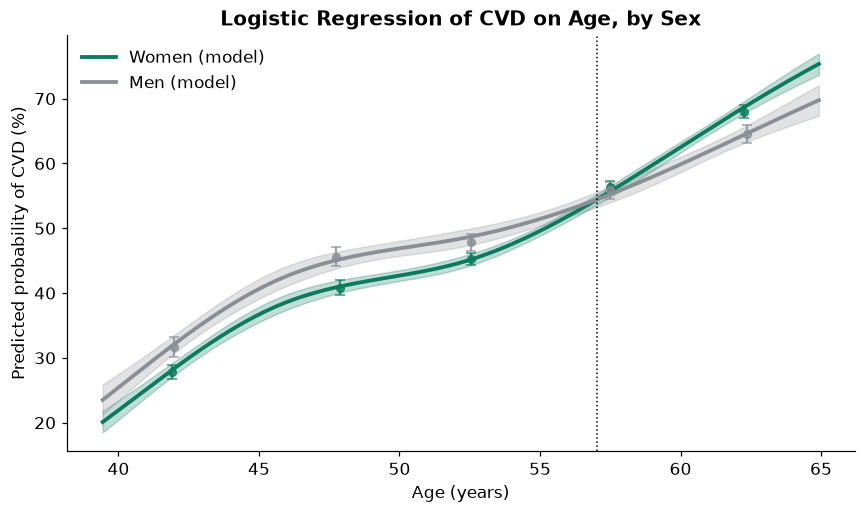

In [9]:
F_CURVE = f"{OUTCOME} ~ female * cr(age_years, df=4, constraints='center')"
m_curve = smf.glm(F_CURVE, data=data, family=sm.families.Binomial()).fit()

AGE_GRID = np.linspace(data["age_years"].quantile(0.005), data["age_years"].max(), 300)

def curve_predictions(model):
    out = {}
    for sex, f in (("Women", 1), ("Men", 0)):
        grid = pd.DataFrame({"age_years": AGE_GRID, "female": f})
        out[sex] = model.get_prediction(grid).summary_frame(alpha=0.05)
    return out

def curve_crossing(model):
    """First age at which the women's curve rises above the men's curve."""
    grid_w = pd.DataFrame({"age_years": AGE_GRID, "female": 1})
    grid_m = pd.DataFrame({"age_years": AGE_GRID, "female": 0})
    diff = np.asarray(model.predict(grid_w)) - np.asarray(model.predict(grid_m))
    up = np.where((diff[:-1] < 0) & (diff[1:] >= 0))[0]
    if len(up) == 0:
        return np.nan
    i = up[0]
    return AGE_GRID[i] + (AGE_GRID[i + 1] - AGE_GRID[i]) * (-diff[i]) / (diff[i + 1] - diff[i])

curves = curve_predictions(m_curve)
cross = curve_crossing(m_curve)
cross_boot = bootstrap(lambda s: curve_crossing(smf.glm(F_CURVE, data=s, family=sm.families.Binomial()).fit()), data)
cross_lo, cross_hi = np.nanpercentile(cross_boot, [2.5, 97.5])
print(f"Curves cross at age {cross:.1f} (95% CI {cross_lo:.1f} to {cross_hi:.1f}); "
      f"a crossing was found in {np.isfinite(cross_boot).mean():.0%} of bootstrap samples")

fig, ax = plt.subplots(figsize=(8, 4.8))
for sex in ["Women", "Men"]:
    c = curves[sex]
    ax.plot(AGE_GRID, 100 * c["mean"], color=SEX_COLORS[sex], lw=2.5, label=f"{sex} (model)")
    ax.fill_between(AGE_GRID, 100 * c["mean_ci_lower"], 100 * c["mean_ci_upper"], color=SEX_COLORS[sex], alpha=0.25)
    b = bands[bands["sex"] == sex]
    ax.errorbar(b["mean_age"], b["pct"], yerr=[b["pct"] - b["lo"], b["hi"] - b["pct"]], fmt="o", ms=5,
                capsize=3, color=SEX_COLORS[sex], alpha=0.8)
ax.axvline(cross, color="black", ls=":", lw=1)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Predicted probability of CVD (%)")
ax.set_title("Logistic Regression of CVD on Age, by Sex")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
save(fig, "regression_curve.png")
plt.show()

### 3d. Do the same risk factors matter for women and men?

We fit the adjusted model separately for women and for men and show the odds ratios side by side in a **forest plot**. Each dot is an odds ratio and each line its 95% confidence interval. A dot to the right of the dashed line (OR = 1) means higher odds of CVD; to the left, lower odds. The x-axis is on a log scale so that an OR of 2 and an OR of 0.5 sit the same distance from 1.

We then test formally whether any factor differs by sex: a **likelihood-ratio test** compares a model where every factor can differ by sex with one where they cannot. Because we look at ten factors, we adjust the individual p-values for multiple comparisons (the Holm method), which guards against finding a difference by chance.

Women                  Men               
                                     OR CI low CI high    OR CI low CI high
10 years older                     1.73   1.67    1.79  1.55   1.48    1.61
Systolic BP 10 mmHg higher         1.83   1.80    1.86  1.86   1.81    1.90
Cholesterol above normal           1.43   1.34    1.53  1.53   1.39    1.68
Cholesterol well above normal      3.01   2.76    3.28  2.97   2.63    3.35
Glucose above normal               1.00   0.92    1.09  1.05   0.93    1.19
Glucose well above normal          0.74   0.67    0.81  0.64   0.56    0.73
BMI 5 units higher                 1.13   1.10    1.15  1.24   1.20    1.28
Smokes (self-reported)             0.91   0.77    1.07  0.86   0.79    0.92
Drinks alcohol (self-reported)     0.81   0.71    0.93  0.80   0.72    0.89
Physically active (self-reported)  0.82   0.78    0.87  0.74   0.69    0.80

Likelihood-ratio test, any factor differs by sex: chi2 = 55.1, df = 10, p = 3.1e-08


,Ratio of ORs (women ÷ men),CI low,CI high,p-value,Holm-adjusted p
10 years older,1.119,1.060,1.182,0.000,0.000
Systolic BP 10 mmHg higher,0.983,0.955,1.013,0.263,1.000
Cholesterol above normal,0.937,0.836,1.051,0.266,1.000
Cholesterol well above normal,1.014,0.874,1.176,0.858,1.000
Glucose above normal,0.949,0.817,1.103,0.496,1.000
Glucose well above normal,1.151,0.976,1.356,0.094,0.656
BMI 5 units higher,0.908,0.872,0.947,0.000,0.000
Smokes (self-reported),1.058,0.881,1.271,0.544,1.000
Drinks alcohol (self-reported),1.010,0.848,1.203,0.908,1.000
Physically active (self-reported),1.113,1.017,1.218,0.020,0.162


Saved HeartBeat-OpenDatathon/track-02/team/figures/forest_plot.png


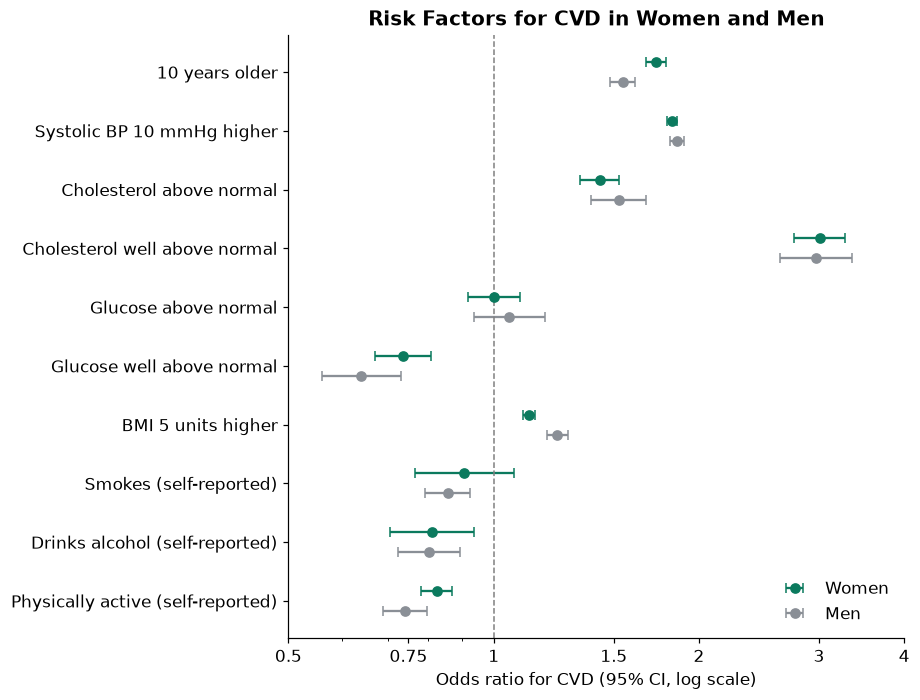

In [10]:
F_STRAT = f"{OUTCOME} ~ age_dec + {COV}"
strat = {}
for sex in ["Women", "Men"]:
    m = smf.logit(F_STRAT, data=data[data["sex"] == sex]).fit(disp=False)
    c = m.conf_int()
    strat[sex] = pd.DataFrame({"OR": np.exp(m.params), "CI low": np.exp(c[0]), "CI high": np.exp(c[1])}).drop(index="Intercept")

side_by_side = pd.concat(strat, axis=1)
side_by_side.index = [LABELS[i] for i in side_by_side.index]
display(side_by_side.round(2))

# Formal test: can every factor differ by sex?
F_INTER = f"{OUTCOME} ~ female * (age_dec + {COV})"
F_COMMON = f"{OUTCOME} ~ female + age_dec + {COV}"
m_inter = smf.logit(F_INTER, data=data).fit(disp=False)
m_common = smf.logit(F_COMMON, data=data).fit(disp=False)
lr = 2 * (m_inter.llf - m_common.llf)
df_lr = int(m_inter.df_model - m_common.df_model)
print(f"Likelihood-ratio test, any factor differs by sex: chi2 = {lr:.1f}, df = {df_lr}, p = {stats.chi2.sf(lr, df_lr):.2g}")

terms = ["age_dec"] + COVARIATES
inter = pd.DataFrame({
    "Ratio of ORs (women ÷ men)": [np.exp(m_inter.params[f"female:{t}"]) for t in terms],
    "CI low": [np.exp(m_inter.conf_int().loc[f"female:{t}", 0]) for t in terms],
    "CI high": [np.exp(m_inter.conf_int().loc[f"female:{t}", 1]) for t in terms],
    "p-value": [m_inter.pvalues[f"female:{t}"] for t in terms],
}, index=[LABELS[t] for t in terms])
inter["Holm-adjusted p"] = multipletests(inter["p-value"], method="holm")[1]
display(inter.round(3))

# Forest plot
order = list(LABELS.values())
fig, ax = plt.subplots(figsize=(8.5, 6.5))
y = np.arange(len(order))[::-1]
for sex, shift in (("Women", 0.17), ("Men", -0.17)):
    t = strat[sex].rename(index=LABELS).loc[order]
    ax.errorbar(t["OR"], y + shift, xerr=[t["OR"] - t["CI low"], t["CI high"] - t["OR"]], fmt="o", ms=6,
                capsize=3, color=SEX_COLORS[sex], label=sex)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, order)
ax.set_xlabel("Odds ratio for CVD (95% CI, log scale)")
ax.set_title("Risk Factors for CVD in Women and Men")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "forest_plot.png")
plt.show()

**Reading the forest plot.** Blood pressure, age and cholesterol have the largest odds ratios for both sexes, and for most factors women's and men's estimates overlap. The formal test says at least one factor differs by sex, and after correcting for multiple comparisons **two** do: **age** (a steeper rise for women, our main result) and **BMI** (linked less strongly to CVD in women: about 13% higher odds per 5 BMI units, against about 24% in men). Physical activity looks slightly less protective in women, but that difference does not survive the correction, so we do not claim it.

Results:
- **Glucose well above normal has an OR below 1.** High glucose and very high cholesterol travel together in this data (see the check in Step 4), so once cholesterol is in the model, the two compete to explain the same people. People diagnosed with diabetes may also already be on treatment. This is not evidence that high glucose protects the heart.
- **Smoking and alcohol have ORs at or below 1.** These are self-reported at the same visit as the CVD record, so people who already know they have heart disease may have quit or may under-report. This is a known problem with cross-sectional data.
- **Physical activity has an OR below 1** for both sexes, which matches the wider literature, but it is also self-reported.

### 3e. Age-adjusted tests: four ways of taking age out of the comparison

Age is the strongest confounder in this dataset because older people have more CVD and higher blood pressure, cholesterol and BMI. So a risk factor can look important just because it is more common in older people. Each test below removes age in a different way, so we can see which results depend on how we handle age and which do not.

| Test | Question | How age is removed |
|---|---|---|
| 1. Age-standardized rates | Do women and men differ in CVD and risk factors once their age mix is made identical? | Direct standardization: each sex is re-weighted to the same age distribution (everyone in the dataset) |
| 2. Age-only vs fully adjusted | What is each factor's link to CVD in women after removing age alone, and how much of it is shared with other factors? | A separate logistic model for each factor with only age added, compared with the full model from 3d |
| 3. Cochran-Mantel-Haenszel (CMH) | Is each risk factor linked to CVD in women *within* age groups, and is the link the same in every age group? | Compares people only within the same five-year age group, then pools; the Breslow-Day test checks whether the link changes across age groups |
| 4. Before vs after 55 | Do risk factors carry different weight for women under 55 and 55 or older? | Splits at 55 (the end of the usual menopause window and close to the median age) and adjusts for age within each group; a version with continuous age checks the cut-off |

Tests 3 and 4 run many comparisons, so we use Holm-adjusted p-values.

In [11]:
# Test 1: age-standardized percentages (direct standardization)
data["sbp_140"] = (data["ap_hi"] >= 140).astype(int)     # systolic 140 mmHg or higher (stage 2 hypertension range)
data["obese"] = (data["bmi"] >= 30).astype(int)          # standard obesity cut-off
data["gluc_high"] = (data["gluc"] > 1).astype(int)       # glucose above normal or higher
STD_WEIGHTS = data["age_band"].value_counts(normalize=True).reindex(AGE_BAND_LABELS)

BINARY_FACTORS = {
    "sbp_140": "Systolic BP 140 mmHg or higher",
    "chol_high": "Cholesterol above normal",
    "gluc_high": "Glucose above normal",
    "obese": "Obesity (BMI 30 or higher)",
    "smoke": "Smokes (self-reported)",
    "alco": "Drinks alcohol (self-reported)",
    "active": "Physically active (self-reported)",
}

def age_standardized(frame, var):
    g = frame.groupby("age_band", observed=True)[var].agg(["mean", "size"]).reindex(AGE_BAND_LABELS)
    rate = (STD_WEIGHTS * g["mean"]).sum()
    se = np.sqrt((STD_WEIGHTS ** 2 * g["mean"] * (1 - g["mean"]) / g["size"]).sum())
    return rate, se

rows = []
for var, label in {"cardio": "Has CVD", **BINARY_FACTORS}.items():
    rw, sew = age_standardized(data[data["sex"] == "Women"], var)
    rm, sem = age_standardized(data[data["sex"] == "Men"], var)
    diff, sed = rw - rm, np.sqrt(sew ** 2 + sem ** 2)
    rows.append({"Measure": label, "Women (%)": 100 * rw, "Men (%)": 100 * rm,
                 "Difference, women - men (points)": 100 * diff,
                 "CI low": 100 * (diff - 1.96 * sed), "CI high": 100 * (diff + 1.96 * sed)})
std_table = pd.DataFrame(rows).set_index("Measure")
print("Age-standardized to the age distribution of everyone in the dataset:")
display(std_table.round(1))

Age-standardized to the age distribution of everyone in the dataset:


,Women (%),Men (%),"Difference, women - men (points)",CI low,CI high
Measure,,,,,
Has CVD,49.0,50.2,-1.2,-2.0,-0.4
Systolic BP 140 mmHg or higher,25.8,28.9,-3.1,-3.8,-2.4
Cholesterol above normal,26.1,23.0,3.0,2.3,3.7
Glucose above normal,15.4,14.2,1.3,0.7,1.8
Obesity (BMI 30 or higher),29.6,19.6,9.9,9.3,10.6
Smokes (self-reported),1.8,21.9,-20.1,-20.6,-19.5
Drinks alcohol (self-reported),2.5,10.6,-8.1,-8.5,-7.6
Physically active (self-reported),80.2,80.7,-0.5,-1.1,0.1


**What Test 1 shows.** Once age is evened out, women and men have almost the same overall share with CVD (about 49% vs 50%; women are 1.2 percentage points lower, 95% CI 0.4 to 2.0). That single average hides the crossover from Step 2: women are lower when younger and higher when older, and the two roughly cancel out. Age-standardized risk factor profiles differ clearly, though. Women are less likely to have systolic pressure of 140 or more, but more likely to have high cholesterol and much more likely to have obesity (about 30% vs 20%). The women and men in this dataset have similar average ages (53.4 vs 53.1), so the standardized numbers are close to the raw ones in 2a.

,Age-only OR,Age-only CI low,Age-only CI high,Fully adjusted OR,Full CI low,Full CI high
Factor,,,,,,
Systolic BP 10 mmHg higher,1.92,1.89,1.95,1.83,1.80,1.86
Cholesterol above normal,1.76,1.66,1.86,1.43,1.34,1.53
Cholesterol well above normal,3.62,3.38,3.87,3.01,2.76,3.28
Glucose above normal,1.49,1.38,1.60,1.00,0.92,1.09
Glucose well above normal,1.63,1.52,1.76,0.74,0.67,0.81
BMI 5 units higher,1.40,1.37,1.42,1.13,1.10,1.15
Smokes (self-reported),1.01,0.87,1.17,0.91,0.77,1.07
Drinks alcohol (self-reported),1.05,0.93,1.18,0.81,0.71,0.93
Physically active (self-reported),0.86,0.82,0.90,0.82,0.78,0.87


Saved HeartBeat-OpenDatathon/track-02/team/figures/age_adjusted_vs_full.png


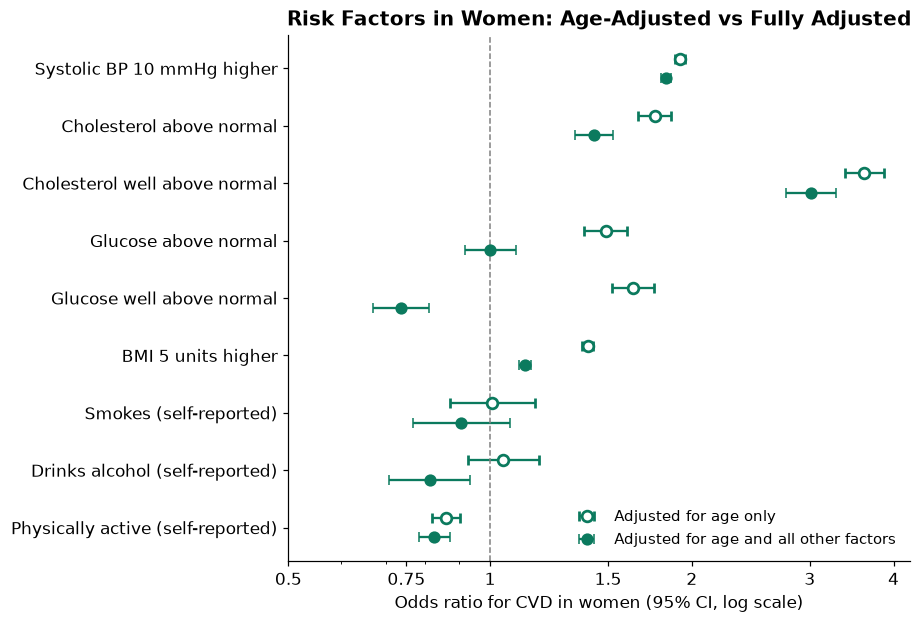

In [12]:
# Test 2: each factor with only age adjusted, compared with the full model (women)
women = data[data["sex"] == "Women"].copy()
BLOCKS = [["sbp_10"], ["chol_2", "chol_3"], ["gluc_2", "gluc_3"], ["bmi_5"], ["smoke"], ["alco"], ["active"]]
rows = []
for block in BLOCKS:
    m = smf.logit(f"{OUTCOME} ~ age_dec + " + " + ".join(block), data=women).fit(disp=False)
    for t in block:
        c = m.conf_int().loc[t]
        rows.append({"Factor": LABELS[t], "Age-only OR": np.exp(m.params[t]),
                     "Age-only CI low": np.exp(c[0]), "Age-only CI high": np.exp(c[1])})
age_only = pd.DataFrame(rows).set_index("Factor")
full_w = strat["Women"].rename(index=LABELS).rename(columns={"OR": "Fully adjusted OR", "CI low": "Full CI low",
                                                            "CI high": "Full CI high"})
compare = age_only.join(full_w)
display(compare.round(2))

order = list(compare.index)
fig, ax = plt.subplots(figsize=(8.5, 5.8))
y = np.arange(len(order))[::-1]
a, f = compare["Age-only OR"], compare["Fully adjusted OR"]
ax.errorbar(a, y + 0.17, xerr=[a - compare["Age-only CI low"], compare["Age-only CI high"] - a], fmt="o", ms=7,
            mfc="white", mew=1.8, capsize=3, color=WOMEN_COLOR, label="Adjusted for age only")
ax.errorbar(f, y - 0.17, xerr=[f - compare["Full CI low"], compare["Full CI high"] - f], fmt="o", ms=7,
            capsize=3, color=WOMEN_COLOR, label="Adjusted for age and all other factors")
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, order)
ax.set_xlabel("Odds ratio for CVD in women (95% CI, log scale)")
ax.set_title("Risk Factors in Women: Age-Adjusted vs Fully Adjusted")
ax.legend(frameon=False, loc="lower right", fontsize=10)
plt.tight_layout()
save(fig, "age_adjusted_vs_full.png")
plt.show()

**What Test 2 shows.** With only age removed, every clinical measure is linked to higher odds of CVD in women, including glucose: glucose well above normal goes with about 1.6 times the odds of same-age women with normal glucose. In the full model that flips below 1. So the "protective" glucose result in 3d is not about glucose itself. It appears only once cholesterol is in the model, because the two overlap so heavily (43% of women and men with very high cholesterol also have very high glucose). Cholesterol and BMI also shrink after full adjustment, meaning part of their link is shared with blood pressure. Blood pressure barely changes (1.92 vs 1.83 per 10 mmHg), so its link does not depend on the other factors. Smoking and alcohol are close to 1 even with only age adjusted, which fits under-reporting or quitting after diagnosis rather than a real protective effect.

In [13]:
# Test 3: Cochran-Mantel-Haenszel tests within five-year age groups (women)
from statsmodels.stats.contingency_tables import StratifiedTable

def cmh(frame, var):
    tables = []
    for _, g in frame.groupby("age_band", observed=True):
        t = pd.crosstab(g[var], g[OUTCOME]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
        tables.append(t)
    st = StratifiedTable(tables)
    lo, hi = st.oddsratio_pooled_confint()
    return {"Age-adjusted OR (CMH)": st.oddsratio_pooled, "CI low": lo, "CI high": hi,
            "p-value": st.test_null_odds().pvalue, "Breslow-Day p (same in every age group?)": st.test_equal_odds().pvalue}

cmh_table = pd.DataFrame({label: cmh(women, var) for var, label in BINARY_FACTORS.items()}).T
cmh_table["Holm-adjusted p"] = multipletests(cmh_table["p-value"], method="holm")[1]
cmh_table["Holm-adjusted Breslow-Day p"] = multipletests(cmh_table["Breslow-Day p (same in every age group?)"], method="holm")[1]
display(cmh_table.round(4))

# Odds ratio in each age group, for the factors whose link changes with age
per_band = {}
for var in ["sbp_140", "chol_high", "gluc_high", "obese"]:
    per_band[BINARY_FACTORS[var]] = [
        StratifiedTable([pd.crosstab(g[var], g[OUTCOME]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()]).oddsratio_pooled
        for _, g in women.groupby("age_band", observed=True)]
print("Odds ratio within each age group (women):")
display(pd.DataFrame(per_band, index=AGE_BAND_LABELS).T.round(2))

,Age-adjusted OR (CMH),CI low,CI high,p-value,Breslow-Day p (same in every age group?),Holm-adjusted p,Holm-adjusted Breslow-Day p
Systolic BP 140 mmHg or higher,7.5227,7.1259,7.9417,0.0000,0.0000,0.0000,0.0000
Cholesterol above normal,2.3781,2.2728,2.4882,0.0000,0.0000,0.0000,0.0000
Glucose above normal,1.5605,1.4790,1.6465,0.0000,0.0000,0.0000,0.0000
Obesity (BMI 30 or higher),1.9067,1.8271,1.9897,0.0000,0.0000,0.0000,0.0000
Smokes (self-reported),1.0093,0.8725,1.1676,0.9008,0.9425,0.9008,1.0000
Drinks alcohol (self-reported),1.0486,0.9280,1.1849,0.4463,0.1236,0.8926,0.3709
Physically active (self-reported),0.8591,0.8187,0.9014,0.0000,0.6448,0.0000,1.0000


Odds ratio within each age group (women):


,Under 45,45-49,50-54,55-59,60-65
Systolic BP 140 mmHg or higher,24.94,13.22,9.92,5.57,4.11
Cholesterol above normal,3.65,2.69,2.39,2.09,2.14
Glucose above normal,2.17,1.73,1.62,1.51,1.26
Obesity (BMI 30 or higher),2.15,2.17,2.07,1.81,1.55


**What Test 3 shows.** Comparing women only with other women in the same five-year age group, systolic pressure of 140 or more is linked to about **7.5 times** the odds of CVD (95% CI about 7.1 to 7.9), by far the strongest link in the data. High cholesterol (about 2.4 times), obesity (about 1.9) and high glucose (about 1.6) follow, and physical activity goes with somewhat lower odds (about 0.86). Smoking and alcohol show no link either way.

The Breslow-Day test says the link is **not** the same in every age group for blood pressure, cholesterol, glucose and obesity: the per-group table shows each one is strongest in the youngest women and weakens with age. For systolic pressure of 140 or more, the odds ratio falls from about 25 in women under 45 to about 4 in women aged 60 to 65.

Women: 24,496 under 55, 20,152 aged 55+
Do any risk factors differ before vs after 55 in women? chi2 = 326.1, df = 9, p = 7.7e-65


,OR under 55,OR 55+,Ratio (55+ ÷ under 55),p-value,Holm-adjusted p,"p, continuous age"
Systolic BP 10 mmHg higher,2.079,1.597,0.768,0.000,0.000,0.000
Cholesterol above normal,1.633,1.243,0.761,0.000,0.000,0.000
Cholesterol well above normal,3.557,2.681,0.754,0.002,0.012,0.000
Glucose above normal,1.086,0.932,0.858,0.086,0.428,0.001
Glucose well above normal,0.773,0.715,0.925,0.436,1.000,0.638
BMI 5 units higher,1.160,1.087,0.937,0.002,0.013,0.002
Smokes (self-reported),0.923,0.871,0.943,0.734,1.000,0.926
Drinks alcohol (self-reported),0.821,0.788,0.959,0.775,1.000,0.744
Physically active (self-reported),0.828,0.820,0.990,0.855,1.000,0.129


Men, for comparison:


,OR under 55,OR 55+,Ratio (55+ ÷ under 55)
Systolic BP 10 mmHg higher,2.14,1.62,0.76
Cholesterol above normal,1.74,1.28,0.74
Cholesterol well above normal,3.65,2.55,0.70
Glucose above normal,1.15,1.00,0.87
Glucose well above normal,0.59,0.68,1.14
BMI 5 units higher,1.27,1.18,0.93
Smokes (self-reported),0.84,0.87,1.04
Drinks alcohol (self-reported),0.76,0.86,1.14
Physically active (self-reported),0.78,0.70,0.90


Does the before/after-55 change differ between women and men? chi2 = 4.2, df = 9, p = 0.9
Women recorded at exactly 120 or 140 mmHg:


,Age group,Systolic BP (mmHg),Women,Has CVD (%),CI low,CI high
0,Under 55,120,10007,27.7,26.8,28.5
1,Under 55,140,2697,81.8,80.3,83.2
2,55+,120,7538,48.5,47.3,49.6
3,55+,140,3260,81.9,80.6,83.2


Saved HeartBeat-OpenDatathon/track-02/team/figures/women_before_after_55.png


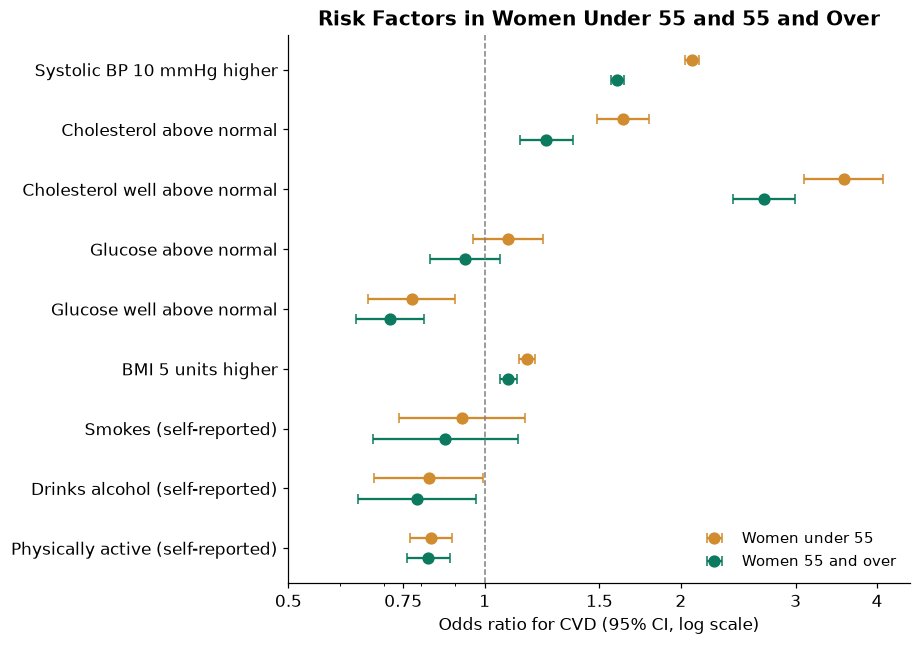

In [14]:
# Test 4: do risk factors carry different weight before and after age 55?
CUT = 55
data["age_55plus"] = (data["age_years"] >= CUT).astype(int)
women = data[data["sex"] == "Women"].copy()
men = data[data["sex"] == "Men"].copy()

def before_after(frame):
    m = smf.logit(f"{OUTCOME} ~ age_dec + age_55plus * ({COV})", data=frame).fit(disp=False)
    m0 = smf.logit(f"{OUTCOME} ~ age_dec + age_55plus + {COV}", data=frame).fit(disp=False)
    mc = smf.logit(f"{OUTCOME} ~ age_dec * ({COV})", data=frame).fit(disp=False)   # age as continuous, no cut-off
    rows = {}
    for t in COVARIATES:
        under, over, ratio = combine(m, [t]), combine(m, [t, f"age_55plus:{t}"]), combine(m, [f"age_55plus:{t}"])
        rows[LABELS[t]] = {"OR under 55": np.exp(under[0]), "Under CI low": np.exp(under[1]), "Under CI high": np.exp(under[2]),
                           "OR 55+": np.exp(over[0]), "55+ CI low": np.exp(over[1]), "55+ CI high": np.exp(over[2]),
                           "Ratio (55+ ÷ under 55)": np.exp(ratio[0]), "p-value": ratio[3],
                           "p, continuous age": mc.pvalues[f"age_dec:{t}"]}
    lr = 2 * (m.llf - m0.llf)
    return pd.DataFrame(rows).T, lr, int(m.df_model - m0.df_model)

ba_w, lr_w, df_w = before_after(women)
ba_w["Holm-adjusted p"] = multipletests(ba_w["p-value"], method="holm")[1]
print(f"Women: {(women.age_55plus == 0).sum():,} under 55, {(women.age_55plus == 1).sum():,} aged 55+")
print(f"Do any risk factors differ before vs after 55 in women? chi2 = {lr_w:.1f}, df = {df_w}, p = {stats.chi2.sf(lr_w, df_w):.2g}")
display(ba_w[["OR under 55", "OR 55+", "Ratio (55+ ÷ under 55)", "p-value", "Holm-adjusted p", "p, continuous age"]].round(3))

ba_m, _, _ = before_after(men)
print("Men, for comparison:")
display(ba_m[["OR under 55", "OR 55+", "Ratio (55+ ÷ under 55)"]].round(2))

# Is the change after 55 different for women and men? (three-way interaction test)
F3_FULL = f"{OUTCOME} ~ female * age_dec + female * age_55plus * ({COV})"
F3_RED = f"{OUTCOME} ~ female * age_dec + female * age_55plus + female * ({COV}) + age_55plus * ({COV})"
m3f = smf.logit(F3_FULL, data=data).fit(disp=False)
m3r = smf.logit(F3_RED, data=data).fit(disp=False)
lr3 = 2 * (m3f.llf - m3r.llf)
df3 = int(m3f.df_model - m3r.df_model)
print(f"Does the before/after-55 change differ between women and men? chi2 = {lr3:.1f}, df = {df3}, p = {stats.chi2.sf(lr3, df3):.2g}")

# Absolute scale: share with CVD at the two most common blood pressure readings
abs_rows = []
for grp, sub in women.groupby("age_55plus"):
    for bp in (120, 140):
        s = sub[sub["ap_hi"] == bp]["cardio"]
        lo, hi = proportion_confint(s.sum(), len(s), method="wilson")
        abs_rows.append({"Age group": "55+" if grp else "Under 55", "Systolic BP (mmHg)": bp, "Women": len(s),
                         "Has CVD (%)": 100 * s.mean(), "CI low": 100 * lo, "CI high": 100 * hi})
print("Women recorded at exactly 120 or 140 mmHg:")
display(pd.DataFrame(abs_rows).round(1))

# Figure: women under 55 vs 55 and over
order = [LABELS[t] for t in COVARIATES]
fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(order))[::-1]
for col, lo, hi, shift, color, label in [("OR under 55", "Under CI low", "Under CI high", 0.17, "#d08c2f", "Women under 55"),
                                         ("OR 55+", "55+ CI low", "55+ CI high", -0.17, WOMEN_COLOR, "Women 55 and over")]:
    t = ba_w.loc[order]
    ax.errorbar(t[col], y + shift, xerr=[t[col] - t[lo], t[hi] - t[col]], fmt="o", ms=7, capsize=3, color=color, label=label)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y, order)
ax.set_xlabel("Odds ratio for CVD (95% CI, log scale)")
ax.set_title("Risk Factors in Women Under 55 and 55 and Over")
ax.legend(frameon=False, loc="lower right", fontsize=10)
plt.tight_layout()
save(fig, "women_before_after_55.png")
plt.show()

**What Test 4 shows.** For women under 55, each 10 mmHg of systolic pressure goes with about 2.1 times the odds of CVD; for women 55 and over, about 1.6 times. Cholesterol and BMI weaken in the same way. These differences are clear after the Holm correction and also when age is treated as continuous, so they do not depend on where we cut.

Two checks keep us from over-reading this:

- **It is not specific to women.** Men show the same weakening (blood pressure about 2.1 under 55 vs about 1.6 at 55 and over), and the three-way test finds no evidence that the change differs by sex. This is a general pattern of aging in this data, not a menopause effect.
- Among women recorded at 140 mmHg, about 82% have CVD in *both* age groups. What changes is the comparison group: at 120 mmHg, about 28% of younger women have CVD against about 49% of older women. When more women at normal readings already have CVD, the *relative* gap shrinks even though high blood pressure is linked to an equally high *absolute* rate. So the weaker odds ratio after 55 does not mean blood pressure is less important for older women.

## Step 4: Check our work

### 4a. How well does the model separate people with and without CVD?

We use **5-fold cross-validation**: split the women into five groups, fit the model on four, predict the fifth, and repeat so every woman is predicted by a model that never saw her. The **AUC** is the chance that the model ranks a random woman with CVD above a random woman without it (0.5 = coin flip, 1 = perfect). We report the mean and standard deviation across the five folds.

We also add predictors in blocks to see what each block contributes beyond age and blood pressure (starter question 3).

In [15]:
def cv_auc(formula, frame, k=5, seed=SEED):
    folds = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    aucs, oof = [], pd.Series(np.nan, index=frame.index)
    for train_idx, test_idx in folds.split(frame, frame[OUTCOME]):
        train, test = frame.iloc[train_idx], frame.iloc[test_idx]
        p = smf.logit(formula, data=train).fit(disp=False).predict(test)
        oof.iloc[test_idx] = np.asarray(p)
        aucs.append(roc_auc_score(test[OUTCOME], p))
    return np.mean(aucs), np.std(aucs, ddof=1), oof

women = data[data["sex"] == "Women"].copy()
blocks = {
    "Age only": "cardio ~ age_dec",
    "Age + blood pressure": "cardio ~ age_dec + sbp_10",
    "+ cholesterol and glucose": "cardio ~ age_dec + sbp_10 + chol_2 + chol_3 + gluc_2 + gluc_3",
    "+ BMI and lifestyle (full)": F_STRAT,
}
auc_rows, oof_full = {}, None
for name, f in blocks.items():
    mean, sd, oof = cv_auc(f, women)
    auc_rows[name] = {"Cross-validated AUC": mean, "SD across folds": sd}
    oof_full = oof
auc_table = pd.DataFrame(auc_rows).T
display(auc_table.round(3))
main_auc, main_sd, _ = cv_auc(F_ADJ, data)
print(f"Main model (women and men together): cross-validated AUC = {main_auc:.3f} (SD {main_sd:.3f})")

,Cross-validated AUC,SD across folds
Age only,0.647,0.008
Age + blood pressure,0.781,0.004
+ cholesterol and glucose,0.792,0.004
+ BMI and lifestyle (full),0.793,0.004


Main model (women and men together): cross-validated AUC = 0.791 (SD 0.004)


### 4b. Are the predicted probabilities honest? (calibration)

AUC only checks ranking. **Calibration** checks whether a predicted 70% chance really means about 70% of those women have CVD. We group women into ten equal groups by predicted risk and compare the average prediction with the observed share. Points on the diagonal mean good calibration.

Saved HeartBeat-OpenDatathon/track-02/team/figures/model_checks.png


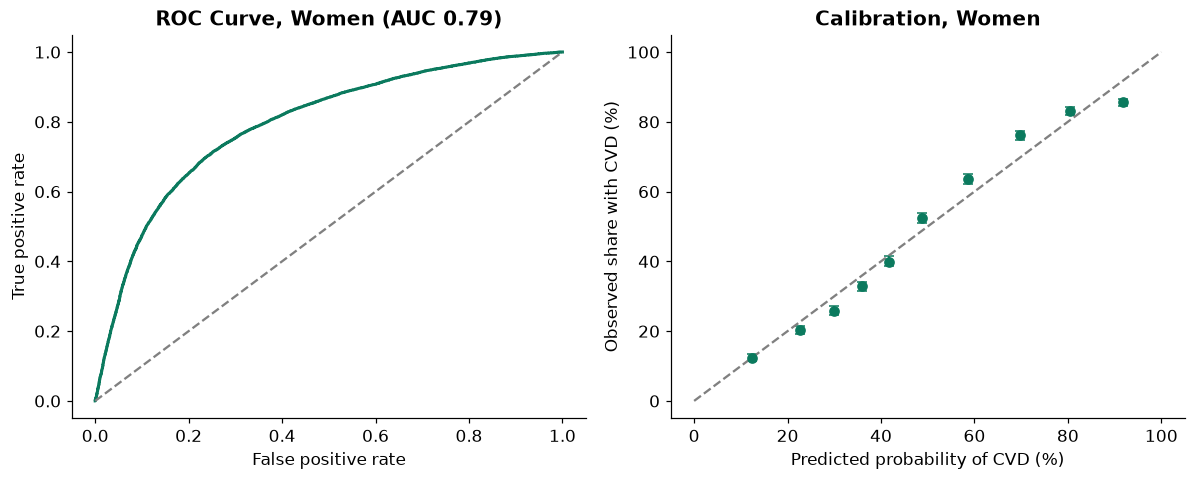

Largest gap between predicted and observed across the ten groups: 6.4 percentage points


In [16]:
cal = pd.DataFrame({"pred": oof_full, "obs": women[OUTCOME]})
cal["decile"] = pd.qcut(cal["pred"], 10, labels=False)
cal_g = cal.groupby("decile").agg(pred=("pred", "mean"), cases=("obs", "sum"), n=("obs", "size"))
lo, hi = proportion_confint(cal_g["cases"], cal_g["n"], method="wilson")
cal_g["obs"] = cal_g["cases"] / cal_g["n"]

fpr, tpr, _ = roc_curve(women[OUTCOME], oof_full)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, color=WOMEN_COLOR, lw=2)
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate",
            title=f"ROC Curve, Women (AUC {auc_table.iloc[-1, 0]:.2f})")
axes[1].errorbar(100 * cal_g["pred"], 100 * cal_g["obs"], yerr=[100 * (cal_g["obs"] - lo), 100 * (hi - cal_g["obs"])],
                 fmt="o", capsize=3, color=WOMEN_COLOR)
axes[1].plot([0, 100], [0, 100], "--", color="grey")
axes[1].set(xlabel="Predicted probability of CVD (%)", ylabel="Observed share with CVD (%)", title="Calibration, Women")
plt.tight_layout()
save(fig, "model_checks.png")
plt.show()
print(f"Largest gap between predicted and observed across the ten groups: "
      f"{100 * (cal_g['obs'] - cal_g['pred']).abs().max():.1f} percentage points")

**What the checks say.** The ROC curve and an AUC of about 0.79 mean the model separates women with and without CVD reasonably well, about as well as published models built on similar exam data. Calibration is good overall but not perfect: the points follow a gentle S-shape around the diagonal, so the model somewhat under-predicts CVD for women with predicted risks of 50-70% and over-predicts it for the highest-risk group, with gaps of up to about 6 percentage points. We tried letting blood pressure bend (a spline instead of a straight line) and it helped only slightly. Blood pressure in this file is heavily rounded (about 4 in 10 women are recorded at exactly 120 mmHg), which limits how finely any model can separate people.

Our question is about **comparing** age slopes between women and men, not predicting an individual woman's risk, so this mild miscalibration does not undermine our conclusion. To be sure, one sensitivity version below uses the flexible blood pressure curve.

### 4c. Is a straight line in age good enough?

Our main model treats age as a straight line on the log-odds scale. We compare it with the flexible spline version using a likelihood-ratio test, and we test whether the flexible age curve differs by sex. If the second test is clearly significant, the women-vs-men difference is not an artefact of forcing a straight line.

We also check how strongly glucose and cholesterol go together, which explains the surprising glucose result in 3d.

In [17]:
SPL = "cr(age_years, df=4, constraints='center')"
m_lin = smf.logit(F_ADJ, data=data).fit(disp=False)
m_spl_int = smf.logit(f"{OUTCOME} ~ female * {SPL} + {COV}", data=data).fit(disp=False)
m_spl_noint = smf.logit(f"{OUTCOME} ~ female + {SPL} + {COV}", data=data).fit(disp=False)

print(f"AIC, straight-line age: {m_lin.aic:,.0f}   AIC, spline age: {m_spl_int.aic:,.0f}   (lower is better)")
lr = 2 * (m_spl_int.llf - m_spl_noint.llf)
dfd = int(m_spl_int.df_model - m_spl_noint.df_model)
print(f"Does the flexible age curve differ by sex (adjusted)? chi2 = {lr:.1f}, df = {dfd}, p = {stats.chi2.sf(lr, dfd):.2g}")

print("\nShare of people at each glucose level, within each cholesterol level:")
display((100 * pd.crosstab(data["cholesterol_level"], data["gluc_level"], normalize="index")).round(1))

AIC, straight-line age: 76,875   AIC, spline age: 76,747   (lower is better)
Does the flexible age curve differ by sex (adjusted)? chi2 = 29.0, df = 4, p = 7.7e-06

Share of people at each glucose level, within each cholesterol level:


gluc_level,above normal,normal,well above normal
cholesterol_level,,,
above normal,25.5,70.5,4.0
normal,4.3,92.9,2.8
well above normal,6.4,50.6,43.0


### 4d. Sensitivity analyses: does the main result survive different reasonable choices?

Our main effect size is the **ratio of ORs** (women ÷ men) for each 10 years of age. We refit it under eight alternative decisions. If the estimate stays above 1 in every version, our conclusion does not hinge on any single choice.

| Version | What changes |
|---|---|
| Main analysis | Adjusted model, our cleaning rules |
| Age and sex only | No adjustment for risk factors |
| Stricter cleaning | Systolic 90-200, diastolic 60-120, height 140-200, weight 40-150 |
| Looser cleaning | Systolic 50-300, diastolic 30-200, height 100-250, weight 20-250, no duplicate or BMI rules |
| Rescue typos | Readings with an extra zero (for example 1,000 or 1,400) are divided by 10 instead of removed |
| Add diastolic BP | Adds diastolic pressure to the main model |
| Flexible blood pressure curve | Blood pressure enters as a smooth curve instead of a straight line (see 4b) |
| Every factor differs by sex | All risk factors interact with sex, not just age |
| Ages 40 and over | Drops the small group under 40 |

,n,Ratio of ORs,CI low,CI high,p-value
Version,,,,,
Main analysis,68557,1.119,1.060,1.182,0.0
Age and sex only,68557,1.206,1.149,1.266,0.0
Stricter cleaning,68152,1.119,1.060,1.182,0.0
Looser cleaning,68651,1.118,1.059,1.180,0.0
Rescue typos,69460,1.116,1.058,1.178,0.0
Add diastolic BP,68557,1.118,1.059,1.180,0.0
Flexible blood pressure curve,68557,1.135,1.074,1.199,0.0
Every factor differs by sex,68557,1.119,1.060,1.182,0.0
Ages 40 and over,66700,1.129,1.066,1.195,0.0


Saved HeartBeat-OpenDatathon/track-02/team/figures/sensitivity.png


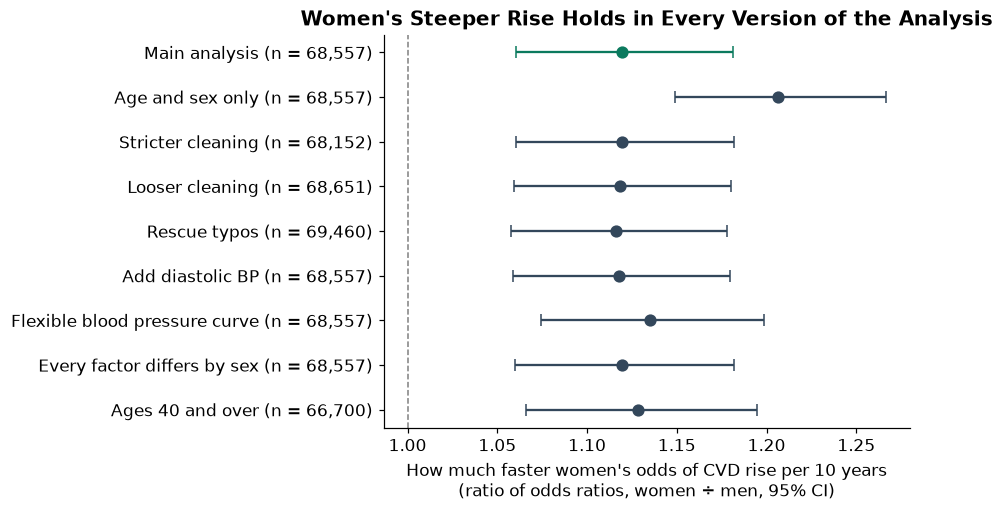

In [18]:
d1_raw = pd.read_csv(find_file("cardiovascular_dataset_OpenBio_Final.csv"), sep=";")

def rebuild(raw, sbp=(70, 250), dbp=(40, 150), height=(120, 220), weight=(30, 200), bmi=(14, 60),
            drop_dupes=True, rescue_typos=False):
    """Re-apply the 01 cleaning rules with different settings."""
    d = raw.drop_duplicates(subset="id").copy()
    if drop_dupes:
        d = d[~d.drop(columns="id").duplicated()]
    if rescue_typos:   # e.g. 1000 -> 100, 1400 -> 140, 14000 -> 140
        for col, top in (("ap_hi", sbp[1]), ("ap_lo", dbp[1])):
            for _ in range(2):
                fix = (d[col] > top) & (d[col] % 10 == 0)
                d.loc[fix, col] = d.loc[fix, col] / 10
    d = d[d["ap_hi"].between(*sbp) & d["ap_lo"].between(*dbp) & d["height"].between(*height)
          & d["weight"].between(*weight) & (d["ap_hi"] > d["ap_lo"])].copy()
    d["bmi"] = d["weight"] / (d["height"] / 100) ** 2
    if bmi:
        d = d[d["bmi"].between(*bmi)]
    d["age_years"] = d["age"] / 365.25
    d["female"] = (d["gender"] == 1).astype(int)
    return add_model_columns(d)

SPECS = [
    ("Main analysis", data, F_ADJ),
    ("Age and sex only", data, F_UNADJ),
    ("Stricter cleaning", rebuild(d1_raw, sbp=(90, 200), dbp=(60, 120), height=(140, 200), weight=(40, 150)), F_ADJ),
    ("Looser cleaning", rebuild(d1_raw, sbp=(50, 300), dbp=(30, 200), height=(100, 250), weight=(20, 250),
                                bmi=None, drop_dupes=False), F_ADJ),
    ("Rescue typos", rebuild(d1_raw, rescue_typos=True), F_ADJ),
    ("Add diastolic BP", data, F_ADJ + " + dbp_10"),
    ("Flexible blood pressure curve", data, F_ADJ.replace("sbp_10", "cr(ap_hi, df=5, constraints='center')")),
    ("Every factor differs by sex", data, F_INTER),
    ("Ages 40 and over", data[data["age_years"] >= 40], F_ADJ),
]
rows = []
for name, frame, formula in SPECS:
    m = smf.logit(formula, data=frame).fit(disp=False)
    est, lo, hi, p = combine(m, ["female:age_dec"])
    rows.append({"Version": name, "n": int(m.nobs), "Ratio of ORs": np.exp(est),
                 "CI low": np.exp(lo), "CI high": np.exp(hi), "p-value": p})
sens = pd.DataFrame(rows).set_index("Version")
display(sens.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
y = np.arange(len(sens))[::-1]
colors = [WOMEN_COLOR if i == 0 else "#33475b" for i in range(len(sens))]
for yi, (_, r), c in zip(y, sens.iterrows(), colors):
    ax.errorbar(r["Ratio of ORs"], yi, xerr=[[r["Ratio of ORs"] - r["CI low"]], [r["CI high"] - r["Ratio of ORs"]]],
                fmt="o", ms=7, capsize=4, color=c)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_yticks(y, [f"{v} (n = {n:,})" for v, n in zip(sens.index, sens["n"])])
ax.set_xlabel("How much faster women's odds of CVD rise per 10 years\n(ratio of odds ratios, women ÷ men, 95% CI)")
ax.set_title("Women's Steeper Rise Holds in Every Version of the Analysis")
plt.tight_layout()
save(fig, "sensitivity.png")
plt.show()

## Step 5: Interpret


In [19]:
u, a = results["Unadjusted"], results["Adjusted"]
def fmt(row, d=2):
    return f"{row['Estimate']:.{d}f} (95% CI {row['CI low']:.{d}f} to {row['CI high']:.{d}f})"

print(f"1. Each additional 10 years of age was associated with {100 * (a.loc['OR per 10 years of age, women', 'Estimate'] - 1):.0f}% higher odds of CVD in women "
      f"(OR {fmt(a.loc['OR per 10 years of age, women'])}) and {100 * (a.loc['OR per 10 years of age, men', 'Estimate'] - 1):.0f}% higher odds in men "
      f"(OR {fmt(a.loc['OR per 10 years of age, men'])}), after accounting for blood pressure, cholesterol, glucose, BMI and lifestyle.")
print(f"2. The ratio of these odds ratios was {fmt(a.loc['Ratio of ORs, women ÷ men'])} adjusted and "
      f"{fmt(u.loc['Ratio of ORs, women ÷ men'])} unadjusted.")
print(f"3. At age 50, women had lower odds of CVD than men (unadjusted OR {fmt(u.loc['OR for women vs men at age 50'])}).")
print(f"4. The smooth age curves for women and men cross at about age {cross:.0f} (95% CI {cross_lo:.0f} to {cross_hi:.0f}).")
print(f"5. The ratio stayed above 1, with a 95% CI excluding 1, in all {len(sens)} versions of the analysis "
      f"(range {sens['Ratio of ORs'].min():.2f} to {sens['Ratio of ORs'].max():.2f}).")
print(f"6. Cross-validated AUC for the women-only model: {auc_table.iloc[-1, 0]:.2f}; "
      f"age and blood pressure alone reach {auc_table.iloc[1, 0]:.2f}.")

1. Each additional 10 years of age was associated with 73% higher odds of CVD in women (OR 1.73 (95% CI 1.67 to 1.79)) and 54% higher odds in men (OR 1.54 (95% CI 1.48 to 1.61)), after accounting for blood pressure, cholesterol, glucose, BMI and lifestyle.
2. The ratio of these odds ratios was 1.12 (95% CI 1.06 to 1.18) adjusted and 1.21 (95% CI 1.15 to 1.27) unadjusted.
3. At age 50, women had lower odds of CVD than men (unadjusted OR 0.89 (95% CI 0.86 to 0.92)).
4. The smooth age curves for women and men cross at about age 57 (95% CI 56 to 59).
5. The ratio stayed above 1, with a 95% CI excluding 1, in all 9 versions of the analysis (range 1.12 to 1.21).
6. Cross-validated AUC for the women-only model: 0.79; age and blood pressure alone reach 0.78.


**What we conclude**

- **Women's chance of CVD rises faster with age than men's in this dataset.** Women start lower: in their 40s, they are noticeably less likely than men to have CVD. In the 55-59 age group the two are about equal, and in their early 60s women are slightly more likely than men to have CVD. The model puts the crossover at about age 57.
- **Part of this travels with blood pressure and cholesterol.** Women's blood pressure and cholesterol rise faster with age than men's. When we account for these readings, the difference in age slopes gets smaller (from a ratio of about 1.21 to about 1.12) but does not disappear. So measured risk factors explain some, not all, of the pattern.
- **The timing fits menopause, but we cannot test that.** The crossover lands in the late 50s, a few years after the usual age of menopause (45 to 55). Dataset 1 has no information on menopause, hormones or treatment, so this link is our speculation.
- **Age-adjusted tests sharpen the risk factor picture.** Among women in the same five-year age group, systolic pressure of 140 or more goes with about 7.5 times the odds of CVD, the strongest link in the data. The "protective" glucose result appears only after adjusting for cholesterol, so it reflects overlap between the two, not a benefit of high glucose. Risk factors' odds ratios are weaker after 55 in women, but equally so in men, and high blood pressure is linked to an equally high absolute rate of CVD (about 82%) before and after 55.
- **Blood pressure carries most of the predictive information.** For women, age and blood pressure alone separate people with and without CVD almost as well as the full model. Cholesterol, glucose, BMI and lifestyle add only a little.

**What we are not claiming**

- That age or sex causes CVD. These are associations in data collected at one point in time.
- That these percentages apply to all women. About half of the people in this dataset have CVD, far more than in the general population, and we do not know how they were selected or where.
- Anything about people outside the binary sex categories recorded in the data.
- Anything about people younger than 39 or older than 65, because the dataset covers only that range.

## Step 6: Headline visual

Our graph shows the smooth model curves from Step 3c with their confidence bands, plus the observed rate in each age group as dots, and marks the crossover age.

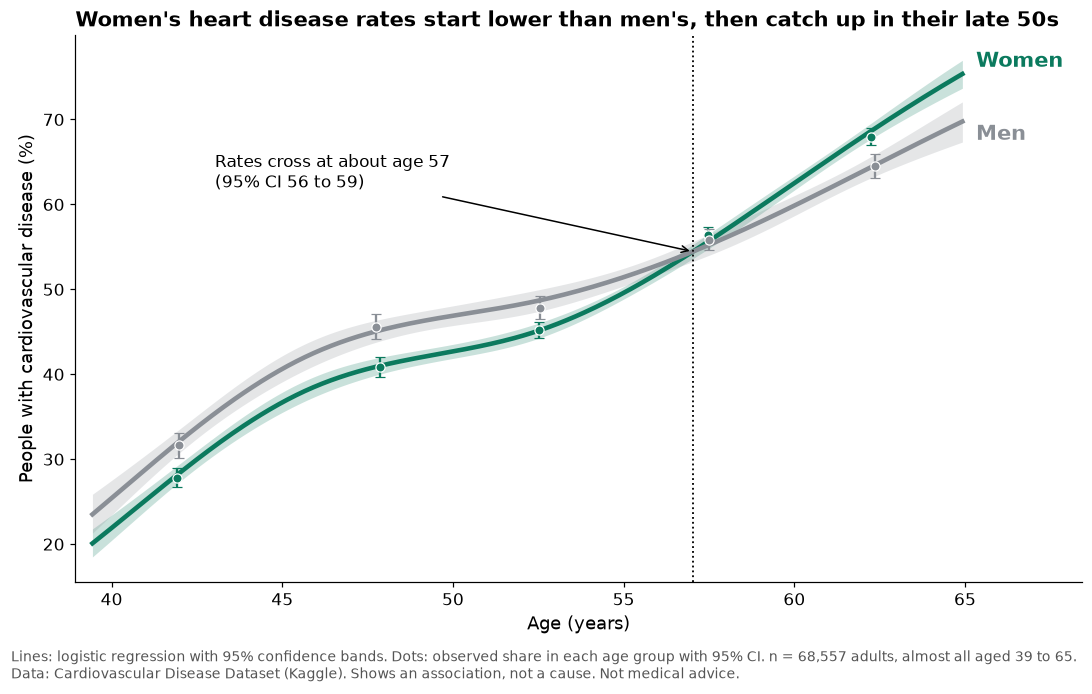

Saved HeartBeat-OpenDatathon/track-02/team/figures/headline.png


In [20]:
HEADLINE_TITLE = "Women's heart disease rates start lower than men's, then catch up in their late 50s"
X_LABEL = "Age (years)"
Y_LABEL = "People with cardiovascular disease (%)"

fig, ax = plt.subplots(figsize=(10, 6))
for sex in ["Women", "Men"]:
    c = curves[sex]
    ax.fill_between(AGE_GRID, 100 * c["mean_ci_lower"], 100 * c["mean_ci_upper"], color=SEX_COLORS[sex], alpha=0.22, lw=0)
    ax.plot(AGE_GRID, 100 * c["mean"], color=SEX_COLORS[sex], lw=3)
    b = bands[bands["sex"] == sex]
    ax.errorbar(b["mean_age"], b["pct"], yerr=[b["pct"] - b["lo"], b["hi"] - b["pct"]], fmt="o", ms=6,
                capsize=3, color=SEX_COLORS[sex], mec="white", mew=0.8)
    end = c.iloc[-1]
    ax.text(AGE_GRID[-1] + 0.4, 100 * end["mean"] + (1.5 if sex == "Women" else -1.5), sex,
            color=SEX_COLORS[sex], fontsize=14, fontweight="bold", va="center")

ax.axvline(cross, color="black", ls=":", lw=1.2)
ax.annotate(f"Rates cross at about age {cross:.0f}\n(95% CI {cross_lo:.0f} to {cross_hi:.0f})",
            xy=(cross, 100 * float(np.interp(cross, AGE_GRID, curves["Women"]["mean"]))),
            xytext=(cross - 14, 62), fontsize=11, arrowprops=dict(arrowstyle="->", color="black", lw=1))
ax.set_xlim(AGE_GRID[0] - 0.5, AGE_GRID[-1] + 3.5)
ax.set_xlabel(X_LABEL, fontsize=12)
ax.set_ylabel(Y_LABEL, fontsize=12)
ax.set_title(HEADLINE_TITLE, fontsize=14, loc="left")
fig.text(0.01, -0.04,
         f"Lines: logistic regression with 95% confidence bands. Dots: observed share in each age group with 95% CI. "
         f"n = {len(data):,} adults, almost all aged 39 to 65.\n"
         "Data: Cardiovascular Disease Dataset (Kaggle). Shows an association, not a cause. Not medical advice.",
         fontsize=9, color="#555555", ha="left")
plt.tight_layout()
fig.savefig(FIGURES / "headline.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved", FIGURES / "headline.png")

## Step 7: Global context from Dataset 3 (countries, not individuals)

Dataset 1 tells us about individuals. Dataset 3 lets us zoom out to ask how CVD in women differs between countries at different levels of development.

Two questions:

1. Is a country's development level (SDI, from 0 to 1) related to its CVD incidence rate in women in 2019 (ASIR, new cases per 100,000 women, age-standardized), or to how that rate **changed** from 1990 to 2019 (EAPC, average yearly percentage change)?
2. How did the **mortality-to-incidence ratio** (MIR: deaths divided by new cases, a rough signal of how deadly the disease is once it occurs) change across SDI levels?

We use linear regression with robust standard errors (HC3), which do not assume that countries vary equally around the line. We report the slope per 0.1 increase in SDI.

Table S2: 204 countries and territories
ASIR in 2019: slope per 0.1 SDI = -4.00 (95% CI -15.35 to 7.35), R-squared = 0.00
EAPC 1990-2019: slope per 0.1 SDI = -0.15 (95% CI -0.19 to -0.12), R-squared = 0.27
Countries where women's CVD incidence rate rose (EAPC interval above 0): 35; fell (below 0): 150; stable (interval includes 0): 19


,region,mir_1990,mir_2019
1,Low,0.49,0.43
2,Low-middle,0.48,0.38
3,Middle,0.50,0.37
4,High-middle,0.46,0.33
5,High,0.29,0.19


Saved HeartBeat-OpenDatathon/track-02/team/figures/global_context.png


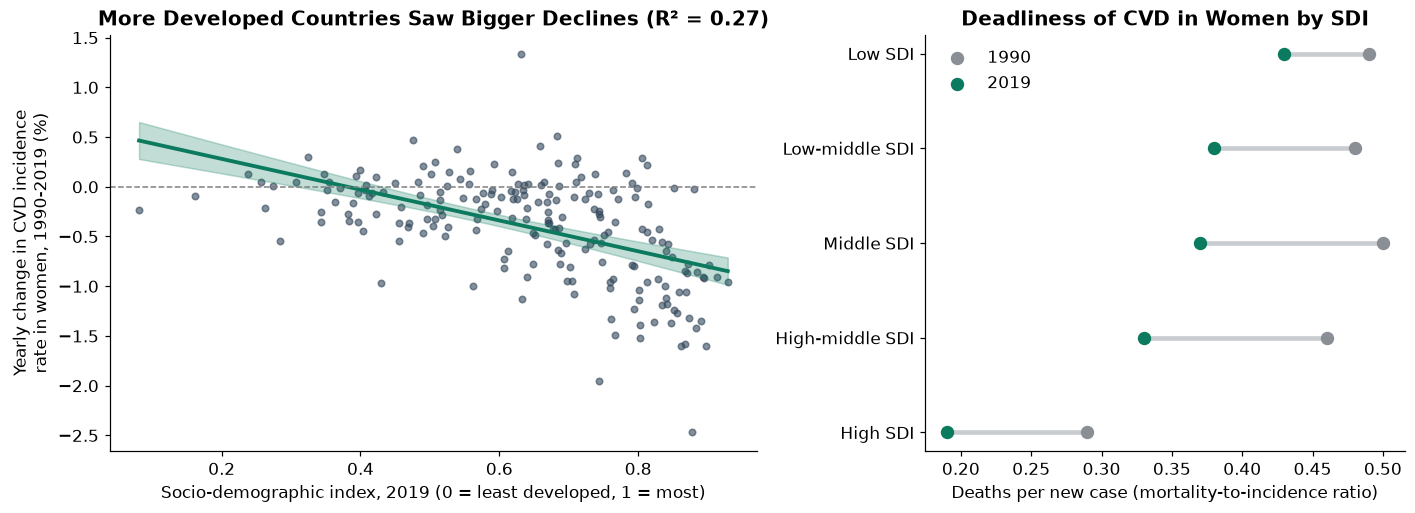

In [21]:
s2 = pd.read_csv(CLEAN / "s2_clean.csv")
s1 = pd.read_csv(CLEAN / "s1_clean.csv")
print(f"Table S2: {len(s2)} countries and territories")

g_fits = {}
for outcome, label in (("asir_2019_est", "ASIR in 2019"), ("eapc_est", "EAPC 1990-2019")):
    m = smf.ols(f"{outcome} ~ sdi_2019", data=s2).fit(cov_type="HC3")
    lo, hi = m.conf_int().loc["sdi_2019"]
    g_fits[outcome] = m
    print(f"{label}: slope per 0.1 SDI = {m.params['sdi_2019'] / 10:.2f} (95% CI {lo / 10:.2f} to {hi / 10:.2f}), "
          f"R-squared = {m.rsquared:.2f}")

rising = (s2["eapc_low"] > 0).sum()
falling = (s2["eapc_high"] < 0).sum()
print(f"Countries where women's CVD incidence rate rose (EAPC interval above 0): {rising}; fell (below 0): {falling}; "
      f"stable (interval includes 0): {len(s2) - rising - falling}")

sdi_rows = s1[s1["section"].astype(str).str.contains("Socio-demographic", na=False)].copy()
display(sdi_rows[["region", "mir_1990", "mir_2019"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})
m = g_fits["eapc_est"]
grid = pd.DataFrame({"sdi_2019": np.linspace(s2["sdi_2019"].min(), s2["sdi_2019"].max(), 100)})
band = m.get_prediction(grid).summary_frame(alpha=0.05)
axes[0].scatter(s2["sdi_2019"], s2["eapc_est"], s=18, color="#33475b", alpha=0.6)
axes[0].plot(grid["sdi_2019"], band["mean"], color=WOMEN_COLOR, lw=2.5)
axes[0].fill_between(grid["sdi_2019"], band["mean_ci_lower"], band["mean_ci_upper"], color=WOMEN_COLOR, alpha=0.25)
axes[0].axhline(0, color="grey", ls="--", lw=1)
axes[0].set(xlabel="Socio-demographic index, 2019 (0 = least developed, 1 = most)",
            ylabel="Yearly change in CVD incidence\nrate in women, 1990-2019 (%)",
            title=f"More Developed Countries Saw Bigger Declines (R² = {m.rsquared:.2f})")

ypos = np.arange(len(sdi_rows))[::-1]
for yi, (_, r) in zip(ypos, sdi_rows.iterrows()):
    axes[1].plot([r["mir_1990"], r["mir_2019"]], [yi, yi], color="#c8ccd0", lw=3, zorder=1)
axes[1].scatter(sdi_rows["mir_1990"], ypos, color=MEN_COLOR, s=60, label="1990", zorder=2)
axes[1].scatter(sdi_rows["mir_2019"], ypos, color=WOMEN_COLOR, s=60, label="2019", zorder=2)
axes[1].set_yticks(ypos, [f"{r} SDI" for r in sdi_rows["region"]])
axes[1].set(xlabel="Deaths per new case (mortality-to-incidence ratio)", title="Deadliness of CVD in Women by SDI")
axes[1].legend(frameon=False, loc="upper left")
plt.tight_layout()
save(fig, "global_context.png")
plt.show()

**What we see (country level only).** A country's development level barely predicts how *often* women develop CVD (R² near 0), but it does predict the *trend*: more developed countries saw larger yearly declines from 1990 to 2019, while many less developed countries stayed flat or rose. And once CVD occurs, it is deadlier in low-SDI regions: around 0.43 deaths per new case in 2019 in the low-SDI group, against about 0.19 in the high-SDI group. The gap between the most and least developed regions was wider in 2019 than in 1990.

**How this connects to Dataset 1.** Dataset 1 shows that women's risk rises steeply with age and travels with blood pressure, a risk factor that can be measured and treated. Dataset 3 suggests that where health systems are stronger, women's CVD incidence fell faster and the disease is less often fatal.

## Step 8 (appendix): Why we did not use Dataset 2

Before choosing a question, we checked whether Dataset 2's outcome can be predicted at all. We used 5-fold cross-validated AUC for a logistic regression and for a flexible machine-learning model (gradient boosting), using every available predictor. If neither beats a coin flip (AUC 0.5), the outcome carries no learnable signal, and any odds ratios from it would describe noise.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

d2 = pd.read_csv(CLEAN / "d2_clean.csv")
D2_FEATURES = ["age", "cholesterol", "heart_rate", "diabetes", "family_history", "smoking", "obesity",
               "alcohol_consumption", "exercise_hours_per_week", "previous_heart_problems", "medication_use",
               "stress_level", "sedentary_hours_per_day", "income", "bmi", "triglycerides",
               "physical_activity_days_per_week", "sleep_hours_per_day", "bp_systolic", "bp_diastolic",
               "diet_code", "female"]
X, y = d2[D2_FEATURES], d2["heart_attack_risk"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, model in [("Logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
                    ("Gradient boosting", HistGradientBoostingClassifier(random_state=SEED))]:
    s = cross_val_score(model, X, y, cv=folds, scoring="roc_auc")
    print(f"{name}: cross-validated AUC = {s.mean():.3f} (SD {s.std(ddof=1):.3f})")
print(f"Share at high risk: women {d2.loc[d2.female == 1, 'heart_attack_risk'].mean():.1%}, "
      f"men {d2.loc[d2.female == 0, 'heart_attack_risk'].mean():.1%}")

Logistic regression: cross-validated AUC = 0.498 (SD 0.006)


Gradient boosting: cross-validated AUC = 0.515 (SD 0.008)
Share at high risk: women 35.6%, men 35.9%


**Result.** Both models score an AUC between 0.50 and 0.52, essentially no better than guessing, and the share at high risk is the same for women and men. Dataset 2 was generated by ChatGPT, and its outcome appears unrelated to its predictors. Any risk factor found in it would be noise, so we did not use it for findings.

---

This notebook is part of a student data analysis for the OpenBio 2026 Datathon. It is not medical advice, a diagnostic tool or clinical guidance. Country-level findings from Dataset 3 do not describe individual people.